# Subword language modeling with a tiny RNN

This notebook keeps the same model progression as the character- and word-level notebooks: bigram, manual RNN, built-in RNN, LSTM, and GRU.

The task is to predict the next subword token. Common words can be single tokens, while rarer words are assembled from reusable pieces instead of becoming `<unk>`.

We train a SentencePiece BPE tokenizer with a target vocabulary of 2,000 pieces, including 256 byte-fallback pieces. The neural architectures and cross-entropy objective are unchanged.

SentencePiece is a project dependency, installed with `uv add sentencepiece`. The tokenizer is trained in memory when the vocabulary cell runs; no tokenizer files are written.

## 1. Start with a small piece of text

A language model learns a conditional distribution: given the tokens so far, what token is likely to come next?

A subword token can be a whole word, part of a word, punctuation, or a fallback byte. We let the tokenizer learn useful pieces from the same corpus as the word-level notebook.

In [ ]:
text = """Alice was beginning to get very tired of sitting by her sister on the bank,and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, "and what is the use of a book," thought Alice "without pictures or conversation?\" """

with open('0305_kmeans_scratch.py', 'r') as f:
    text = f.read()

with open(r"C:\Users\101119\OneDrive\ePUBs\Books and Articles\The Lord of the rings\New Text Document.txt", 'r') as f:
    text = f.read()

# text = text.lower()
print(len(text))
print(text[:500])

2620690
 This tale grew in the telling, until it became a history of the Great War of the Ring and included many glimpses of the yet more ancient history that preceded it. It was begun soon after The Hobbit was written and before its publication in 1937; but I did not go on with this sequel, for I wished first to complete and set in order the mythology and legends of the Elder Days, which had then been taking shape for some years. I desired to do this for my own satisfaction, and I had little hope that 


## 2. Train a subword tokenizer

SentencePiece BPE starts with small symbols and repeatedly merges common pairs. Frequent words may become single tokens; uncommon words can use several smaller pieces.

The target vocabulary is 2,000 entries, including the reserved `<unk>` token and 256 byte-fallback entries. Byte fallback lets unseen characters be encoded without using `<unk>`; generation masks the unused unknown token.

The visible underscore-like marker in a piece represents a word boundary. Decode the complete token-ID sequence to reconstruct text, rather than inserting a space between every piece.

The default normalizer applies Unicode NFKC normalization and collapses whitespace. The tokenizer therefore preserves normalized text, not original indentation or line breaks. A block of 32 tokens is not necessarily 32 words.

In [9]:
import io
import sentencepiece as spm

vocab_size = 2000
model_buffer = io.BytesIO()
spm.SentencePieceTrainer.train(
    sentence_iterator=iter(text.splitlines()),
    model_writer=model_buffer,
    model_type='bpe',
    vocab_size=vocab_size,
    byte_fallback=True,
    character_coverage=1.0,
    bos_id=-1,
    eos_id=-1,
    pad_id=-1,
    hard_vocab_limit=False,
    minloglevel=2,
)
tokenizer = spm.SentencePieceProcessor(model_proto=model_buffer.getvalue())
vocab_size = tokenizer.get_piece_size()
print('subword vocabulary size:', vocab_size)
print('first pieces:', [tokenizer.id_to_piece(index) for index in range(20)])

subword vocabulary size: 2000
first pieces: ['<unk>', '<0x00>', '<0x01>', '<0x02>', '<0x03>', '<0x04>', '<0x05>', '<0x06>', '<0x07>', '<0x08>', '<0x09>', '<0x0A>', '<0x0B>', '<0x0C>', '<0x0D>', '<0x0E>', '<0x0F>', '<0x10>', '<0x11>', '<0x12>']


In [10]:
def encode(s):
    return tokenizer.encode(s, out_type=int)


def decode(ids):
    return tokenizer.decode(list(ids))


example = ' '.join(text.split()[:5])
encoded_example = encode(example)
print('subword pieces:', tokenizer.encode(example, out_type=str))
print('encoded token ids:', encoded_example)
print('decoded back:', decode(encoded_example))
assert decode(encoded_example) == example

rare_example = 'unfamiliarwordxyz ' + chr(0x1F680)
rare_ids = encode(rare_example)
print('rare text:', rare_example)
print('rare text pieces:', tokenizer.encode(rare_example, out_type=str))
print('rare text decoded:', decode(rare_ids))
assert tokenizer.unk_id() not in rare_ids
assert decode(rare_ids) == rare_example

subword pieces: ['▁This', '▁tale', '▁grew', '▁in', '▁the']
encoded token ids: [1483, 1642, 1151, 296, 260]
decoded back: This tale grew in the
rare text: unfamiliarwordxyz 🚀
rare text pieces: ['▁un', 'f', 'am', 'ili', 'ar', 'w', 'ord', 'x', 'y', 'z', '▁', '<0xF0>', '<0x9F>', '<0x9A>', '<0x80>']
rare text decoded: unfamiliarwordxyz 🚀


## 3. Turn text into supervised examples

Encoding text gives a sequence of token IDs. The input is a block of IDs and the target is the same block shifted by one token.

For IDs `[12, 45, 7, 91]`, a three-step training example is:

- input: `[12, 45, 7]`
- target: `[45, 7, 91]`

Each position predicts the next token, even when the next piece continues the same word. Decoded blocks can begin or end inside words; that is expected with subword tokens.

In [11]:
import torch

block_size = 32
encoded = torch.tensor(encode(text), dtype=torch.long)

x = encoded[:block_size]
y = encoded[1:block_size + 1]

print('x shape:', x.shape)
print('y shape:', y.shape)
print('x tokens:', decode(x.tolist()))
print('y tokens:', decode(y.tolist()))

x shape: torch.Size([32])
y shape: torch.Size([32])
x tokens: This tale grew in the telling, until it became a history of the Great War of the Ring and included many glimpses of
y tokens: tale grew in the telling, until it became a history of the Great War of the Ring and included many glimpses of the


## 4. Make batches

Training on a single long sequence of subword tokens is not efficient. Instead, we sample many random blocks from the text and train on them in batches.

This creates a dataset of shape `(batch, time)`. Each input position is a subword token, and the target is the following token.

In [12]:
def get_batch(data, batch_size, block_size):
    starts = torch.randint(len(data) - block_size, (batch_size,))
    xb = torch.stack([data[s:s + block_size] for s in starts])
    yb = torch.stack([data[s + 1:s + 1 + block_size] for s in starts])
    return xb, yb

batch_size = 4
xb, yb = get_batch(encoded, batch_size, block_size)

print('xb shape:', xb.shape)
print('yb shape:', yb.shape)
for i in range(batch_size):
    print(f'example {i}:')
    print('input tokens :', decode(xb[i].tolist()))
    print('target tokens:', decode(yb[i].tolist()))
    print('-' * 30)

xb shape: torch.Size([4, 32])
yb shape: torch.Size([4, 32])
example 0:
input tokens : stand here for ever as a warning.' 'If you had been the first to lift the Orthanc-stone, and not he, how
target tokens: here for ever as a warning.' 'If you had been the first to lift the Orthanc-stone, and not he, how would
------------------------------
example 1:
input tokens : ut of the east the biting wind was blowing. To his right there loomed against the westward stars a dark black shape. A great b
target tokens: of the east the biting wind was blowing. To his right there loomed against the westward stars a dark black shape. A great barrow
------------------------------
example 2:
input tokens : ed the river, which was the original boundary of the land eastwards. He built (and excavated) Brandy
target tokens: the river, which was the original boundary of the land eastwards. He built (and excavated) Brandy H
------------------------------
example 3:
input tokens : and keep your eyes open! ' He s

## 5. Start with a simple baseline

Before adding recurrence, let's build a deliberately weak model.

This model will look at only the current token and try to predict the next one. It cannot know what happened earlier in the sequence. That is the problem we need recurrence to solve.

In [13]:
# sample from the model

@torch.no_grad()
def sample(model, start='The', length=100, temperature=1.0):
    if temperature <= 0:
        raise ValueError('temperature must be positive')
    generated_ids = encode(start)
    if not generated_ids:
        raise ValueError('start must contain at least one token')
    model.eval()
    model_device = next(model.parameters()).device
    h = None
    x = torch.tensor([generated_ids], dtype=torch.long, device=model_device)

    for _ in range(length):
        if isinstance(model, Bigram):
            logits = model(x)
        else:
            logits, h = model(x, h)
        logits = logits[:, -1, :] / temperature
        logits[:, tokenizer.unk_id()] = -float('inf')
        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1).item()
        generated_ids.append(next_id)
        x = torch.tensor([[next_id]], dtype=torch.long, device=model_device)

    return decode(generated_ids)

In [14]:
import torch.nn as nn
import torch.nn.functional as F

class Bigram(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.fc = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        # x shape: (batch, time)
        # logits shape: (batch, time, vocab)
        return self.fc(self.embedding(x))

model = Bigram(vocab_size)
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits = model(xb)
print('logits shape:', logits.shape)
loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))
print('loss:', loss.item())

sample_text = sample(model, start=text.split()[0], length=80)
print('sampled text:', sample_text)

logits shape: torch.Size([8, 16, 2000])
loss: 7.752303600311279
sampled text: This opened9 saderingel� al stair Hold rather sle indeed�illedoose fields�well le meninkool after learn should muchich�well His� loud bit taken late t dreordorc peril never dark1 sky."randowynC clouds�ath vift sword Hisburull now take hidden.’ had FaramirburordW South wizard wild—umpryingbe0 stayldor


Epoch    0, Loss: 7.7857
Epoch  500, Loss: 5.7507
Epoch 1000, Loss: 4.8762
Epoch 1500, Loss: 4.8303
Epoch 2000, Loss: 4.6749
Epoch 2500, Loss: 4.7054
Epoch 3000, Loss: 4.6834
Epoch 3500, Loss: 4.6221
Epoch 4000, Loss: 4.4619
Epoch 4500, Loss: 4.3532
Epoch 4999, Loss: 4.4455


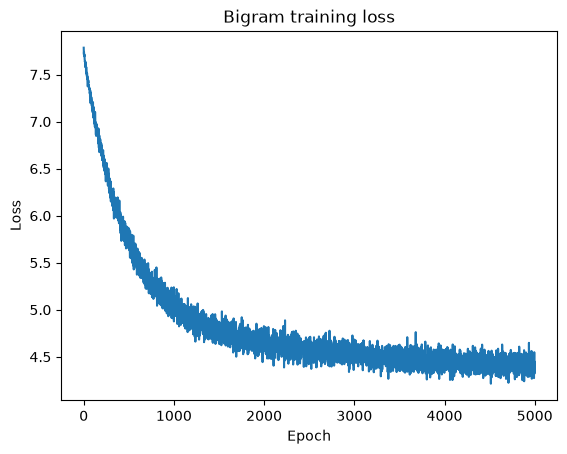

In [15]:
# train the bigram model
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
train_losses = []

for epoch in range(5000):
    xb, yb = get_batch(encoded, batch_size=32, block_size=32)
    optimizer.zero_grad()
    logits = model(xb)
    loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    if epoch % 500 == 0 or epoch == 4999:
        print(f'Epoch {epoch:4d}, Loss: {loss.item():.4f}')

plt.plot(train_losses)
plt.title('Bigram training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [16]:
sample_text = sample(model, start=text.split()[0], length=80)
print('sampled text:', sample_text)

sampled text: This I know the red, and all the falling down to finished Gandalf; and Sam heard in the Warnors should be some wad it is would now, and bighed away. The woods in need all. 'Tori_ feifting after the ous of Lorien: haste has gone. That was a sil wastended it would go quickly a


## 6. Manual recurrence

Now we write the recurrent step explicitly.

The hidden state at time `t` depends on the current token and the previous hidden state:

$$
h_t = f(W_x x_t + W_h h_{t-1} + b)
$$

This gives the network a memory. That memory lets it use earlier tokens to predict the next token.

In [17]:
class TinyRNNManual(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()

        # vocabulary size = number of unique subsubword tokens in text
        # embedding_dim = size of the vector for each subword token id
        # hidden_size = size of the recurrent hidden state
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # x2h: input-to-hidden map
        # input shape: (batch, embedding_dim)
        # output shape: (batch, hidden_size)
        self.x2h = nn.Linear(embedding_dim, hidden_size)

        # h2h: previous hidden-to-current hidden map
        # input shape: (batch, hidden_size)
        # output shape: (batch, hidden_size)
        self.h2h = nn.Linear(hidden_size, hidden_size)

        # h2y: hidden-to-output map
        # input shape: (batch, hidden_size)
        # output shape: (batch, vocab_size)
        self.h2y = nn.Linear(hidden_size, vocab_size)
        self.hidden_size = hidden_size

    def forward(self, x, h=None):
        # x has shape: (batch, time)
        # example: (32, 64) means 32 sequences, each of length 64 tokens

        # if no previous hidden state is supplied, initialise it to zeros
        # h shape: (batch, hidden_size)
        if h is None:
            h = torch.zeros(x.size(0), self.hidden_size, device=x.device)

        # embeddings: convert subword token ids into learned vectors
        # x -> (batch, time)
        # embedding(x) -> (batch, time, embedding_dim)
        embeddings = self.embedding(x)

        outputs = []

        # iterate through the sequence one timestep at a time
        # time dimension is the second axis: x.size(1)
        for t in range(x.size(1)):
            # current token embedding for all examples in the batch
            # xt shape: (batch, embedding_dim)
            xt = embeddings[:, t, :]

            # recurrent update:
            # x2h(xt):   (batch, hidden_size)
            # h2h(h):    (batch, hidden_size)
            # sum:       (batch, hidden_size)
            # tanh:      (batch, hidden_size)
            h = torch.tanh(self.x2h(xt) + self.h2h(h))

            # logits_t predicts the next token for each example at this timestep
            # h2y(h):    (batch, vocab_size)
            logits_t = self.h2y(h)

            # append one timestep of logits to outputs
            # logits_t.unsqueeze(1): (batch, 1, vocab_size)
            outputs.append(logits_t.unsqueeze(1))

        # concatenate along time dimension
        # after concatenation, logits has shape: (batch, time, vocab_size)
        logits = torch.cat(outputs, dim=1)

        return logits, h

manual_model = TinyRNNManual(vocab_size, embedding_dim=16, hidden_size=32)
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits, h = manual_model(xb)
print('manual logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())
sample_text = sample(manual_model, start=text.split()[0], length=80)
print('sampled text from manual RNN:', sample_text)

manual logits shape: torch.Size([8, 16, 2000])
hidden state shape: torch.Size([8, 32])
loss: 7.6160888671875
sampled text from manual RNN: This swordiedadepany they[oon�?So We valley=man1�omet itiff heardipanger Sun Minas st being thateed knownkedound� less ill� eveninguth� Mountainsood faintoodarp7 danger respan usedues- fing Frodo cast?' unless/ greast sightail treesifflight� pass ch?’  horse in� tunmemyond� doom grew


Epoch    0, Loss: 7.6183
Epoch  200, Loss: 6.2529
Epoch  400, Loss: 6.0452
Epoch  600, Loss: 5.9452
Epoch  800, Loss: 5.7051
Epoch 1000, Loss: 5.6352
Epoch 1200, Loss: 5.4312
Epoch 1400, Loss: 5.3069
Epoch 1600, Loss: 5.1860
Epoch 1800, Loss: 5.1306
Epoch 1999, Loss: 5.0260


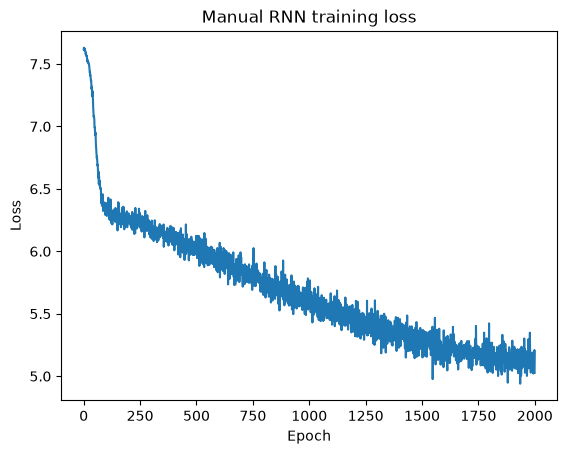

In [18]:
# train the manual RNN model
optimizer = torch.optim.AdamW(manual_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
train_losses = []

for epoch in range(2000):
    xb, yb = get_batch(encoded, batch_size=32, block_size=32)
    optimizer.zero_grad()
    logits, _ = manual_model(xb)
    loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    if epoch % 200 == 0 or epoch == 1999:
        print(f'Epoch {epoch:4d}, Loss: {loss.item():.4f}')

plt.plot(train_losses)
plt.title('Manual RNN training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [19]:
# sample from the manual RNN model
sample_text = sample(manual_model, start=text.split()[0], length=800)
print('sampled text from manual RNN:', sample_text)

sampled text from manual RNN: This forts. But Frodo remem off of a att lengain right lay star for reciouset he reallyrefow said was not thr Come armper and in another long wayot- well. 'It will remain at taken. For you' teots the stars where people onent himself to growck and Ashes, the face. You heard in he think to pe? I was thick. `, see about by at these step, but he do, or a maroseit! ‘Come, if, and or�! was sudden his eyes spoke, not car at he doub crown with my evil. `It of the Dty. The men upon first all. cut hebe to in the pry of hobbits, and further bieing fved the tit into in the helmen grew does. The Mings of the hills on the charn brought to take al would in Cious more lurung of it, as few durs from the any they took a sherua put. The Enemy:s yet of my doors. But Thay up a cror the hills had seen: triever at his breue bl went-ly something. ‘Ille for?' `I not quest I not no old pared. He leave perhaps that am because and see iter tree in your heart and indeed to make the Di

## 7. Use PyTorch's built-in `nn.RNN`

The code above is the same idea as the built-in recurrent layer. PyTorch packages the recurrence into a single module so we can write cleaner code.

The conceptual mapping is:

- subword token -> integer id -> embedding vector
- embedding -> recurrent hidden state
- hidden state -> logits for the next token

This is exactly the sequence architecture we need for subword language modeling.

In [20]:
class TinyRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.RNN(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.rnn(x, h)
        logits = self.fc(out)
        return logits, h

rnn_model = TinyRNN(vocab_size, embedding_dim=12, hidden_size=32)
xb, yb = get_batch(encoded, batch_size=8, block_size=16)
logits, h = rnn_model(xb)
print('logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())

logits shape: torch.Size([8, 16, 2000])
hidden state shape: torch.Size([1, 8, 32])
loss: 7.59659481048584


## 8. Train the model

Now we everything together: sample batches, compute logits, compare them to the shifted targets, backpropagate, and update the parameters.

The loss is standard cross-entropy because the output is a categorical distribution over the vocabulary.

epoch    0 | loss = 7.6203
epoch  200 | loss = 6.2228
epoch  400 | loss = 5.8861
epoch  600 | loss = 5.6458
epoch  800 | loss = 5.3830
epoch 1000 | loss = 5.1918
epoch 1200 | loss = 4.9690
epoch 1400 | loss = 4.9339
epoch 1600 | loss = 4.8076
epoch 1800 | loss = 4.8270
epoch 1999 | loss = 4.8134
final loss: 4.81338357925415


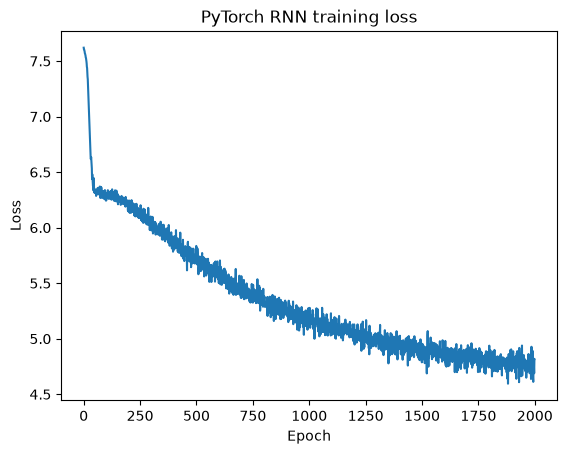

In [21]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = TinyRNN(vocab_size, embedding_dim=16, hidden_size=64).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

encoded_device = encoded.to(device)
losses = []

batch_size = 32
block_size = 64

for epoch in range(2000):
    xb, yb = get_batch(encoded_device, batch_size, block_size)
    logits, _ = model(xb)
    loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if epoch % 200 == 0 or epoch == 1999:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

print('final loss:', losses[-1])

plt.plot(losses)
plt.title('PyTorch RNN training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## 9. Generate new text

Once the model is trained, we can use it in autoregressive generation mode. It predicts one token at a time, feeds that token back in, and keeps going.

This is the same repeated next-token prediction process, now operating on subsubword tokens.

In [22]:
@torch.no_grad()
def generate(model, start_text, length, device=None):
    model_device = next(model.parameters()).device
    if device is not None and torch.device(device) != model_device:
        raise ValueError('device must match the model device')
    return sample(model, start=start_text, length=length)


sample_text = generate(model, 'Age of Middle-earth ', 1200, device)
print(sample_text)

Age of Middle-earthrz died, not steep nor Fue: I did not may have passed on either Shadowon, or their stoning into the mars of the hill of the foot of which strot seen discrow: `It was chesready on more. I tell, but indeed come Baggsed a voice in the thesss and she could see like spearburoudockion began, and the ho days! ‘I have saidt' said Sam. 'Wth'll us go old treetildy there he made sate men. A mnranon: he would St out to Eomer. With vaking that he had been wide green?’ Nould they are not a silence about Frodo caught climb. Wity grramvisement, Legolas’s dreip Theyring for hisled with a pack-coilies they saw three bids of his doubts sthens. There was a long tales, sheraom before it gazed out and better at Be, when of ordordes as for. `There learn as you' go, I really got to be a night. We is the Black journey were in no longer-feowiown that say for thick forward. 'You’ll get us no not.pow in the hand shape, as he is none before him. Suddenly fall, he was already still good him,' sai

## 10. What we have learned

This notebook shows the progression from raw text to a working recurrent language model:

1. Subword pieces become integer token IDs.
2. A sequence of subword tokens becomes supervised training data.
3. A bigram model uses only the current token.
4. A hidden state gives the network memory across the sequence.
5. `nn.RNN` is the packaged version of the recurrence we wrote by hand.
6. Generation is repeated next-token prediction.

This is the conceptual bridge from simple feedforward networks to modern language models.

The next natural step is to use an LSTM or GRU, which are designed to handle longer dependencies more reliably than a bare RNN.

In [23]:
# same example but with an LSTM

class TinyLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.lstm(x, h)
        logits = self.fc(out)
        return logits, h

lstm_model = TinyLSTM(vocab_size, embedding_dim=32, hidden_size=64).to(device)

xb, yb = get_batch(encoded.to(device), batch_size=8, block_size=16)
logits, h = lstm_model(xb)
print('logits shape:', logits.shape)
print('hidden state shapes:', h[0].shape, h[1].shape, 'input:', xb.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())

generated_text = generate(lstm_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

logits shape: torch.Size([8, 16, 2000])
hidden state shapes: torch.Size([1, 8, 64]) torch.Size([1, 8, 64]) input: torch.Size([8, 16])
loss: 7.606351375579834
 gre,'r�man his asSother use8em done betDomet presentence Here afterof	 enemy diff bowlighair Moria did climbed Orcs glH; realbeardrand dreamor Anrand living Thisiftivend Elro everycl Denethor>ft To grew then P forward "cn North�edComeQ h peopleimliat relord Ring sprangilledice whis guard op Hobbit O darkness alwaysaughtV hor creat liill Brandyap Treebeard doniend hidden climb above not sil� To swift alongoo  kind wat" turning�ore voicesantnded mo6 suppriel+) comeseep+ ste light�G4 proՋor Man gu southney met kuck ere$other pres almostf Some stoodten kingers che Mordorrible cry2 recit` alreadyu A words green co� shrken if Afterondr“N sto let stone indichthing stepropartOale la Androdo really8� shadowsB trustf betteriftash{ e�akenamp tou eyesnt+ st em indeed hear Sushar power Moriaollax –lytle foodleepead happ ancient Elrond sof

In [24]:
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
encoded_device = encoded.to(device)

epochs = 5000
for epoch in range(epochs):
    xb, yb = get_batch(encoded_device, batch_size=32, block_size=32)
    logits, _ = lstm_model(xb)
    loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

epoch    0 | loss = 7.6036
epoch  500 | loss = 5.8478
epoch 1000 | loss = 5.3602
epoch 1500 | loss = 5.1551
epoch 2000 | loss = 4.9372
epoch 2500 | loss = 4.9153
epoch 3000 | loss = 4.8521
epoch 3500 | loss = 4.7122
epoch 4000 | loss = 4.6828
epoch 4500 | loss = 4.4312
epoch 4999 | loss = 4.5289


In [25]:
generated_text = generate(lstm_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

Age of Middle-earthlized of the Power towers drew our dreams. Took I go as no same of Wudy?' ' – I get the Ring and light we wantly it to you old my folk asleep, who me. Take that met will go what they date and he was gold. It did not s haden. There was help at to Isengard, to small folk far short blarmed in worthy starting.’ He amower, and using withce between their advings! Upititted to ever the rest. Creeice was not. Shurf4 or feel of you right from a signon. Of it were safe to Gollum always guses; and they were fallen for the lusthing shapinhe spessing hour in the willap, and the City and Shadowfread cievedil, if his certaininess before ahead. Canatable steither the Wame! Where is not known, and a steep errand dims sooink, now son that it was some h hand, and they came tain-et sighed the fay of a few wind sce, from the darkness upon them?plide about his tongited in only me’s lamer, which all clasning hobbits did not know near. Yet Sam went and what you have not stayer to the capes 

In [26]:
# same example but with a GRU

class TinyGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        x = self.embedding(x)
        out, h = self.gru(x, h)
        logits = self.fc(out)
        return logits, h


gru_model = TinyGRU(vocab_size, embedding_dim=32, hidden_size=64).to(device)
xb, yb = get_batch(encoded_device, batch_size=8, block_size=16)
logits, h = gru_model(xb)
print('logits shape:', logits.shape)
print('hidden state shape:', h.shape)
print('loss:', F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())

generated_text = generate(gru_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

logits shape: torch.Size([8, 16, 2000])
hidden state shape: torch.Size([1, 8, 64])
loss: 7.625232219696045
Age of Middle-earth app GollumckIwn small ex trees ac lightbut cloak�aintI diffolasaking night comeumpNotifWh either DwarTh streome,’ fairizard fail seems beyondigh Gimli been How also Smeagolainening thoughPamed said Iping doub why along hornonarn jo veryOove lilm Orcs our heard0 startNoildm stay hear understandcept
ally and one got; stoence Elroisedic rather any so rooomower k mar� speak� an someuchift he wear earthometintopg shapeilt“� three answer Pippiniefck fromcieestern White Gollum never afraid step North say sleepD� Denethorauleepuck Wh Str amlingern hung wordror s behind freehenrmost am� togethercs Cityget turningctItangeott ready– Seich away sound burn did� leastaces step forgords doubt barumpig}ili cliff Anduin bothwaysIt turn�ai running Sam nor eitherZ stood ruin w bro commandth“ount bus st th breath down Com tim green gr escapetovered litouldchay it blable Tirith 

In [29]:
optimizer = torch.optim.Adam(gru_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
encoded_device = encoded.to(device)

epochs = 5000
for epoch in range(epochs):
    xb, yb = get_batch(encoded_device, batch_size=32, block_size=32)
    logits, _ = gru_model(xb)
    loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

epoch    0 | loss = 4.3834
epoch  500 | loss = 4.4698
epoch 1000 | loss = 4.2760
epoch 1500 | loss = 4.2234
epoch 2000 | loss = 4.2097
epoch 2500 | loss = 4.1999
epoch 3000 | loss = 4.1811
epoch 3500 | loss = 4.1835
epoch 4000 | loss = 4.2717
epoch 4500 | loss = 4.2661
epoch 4999 | loss = 4.1420


In [30]:
generated_text = generate(gru_model, 'Age of Middle-earth ', 1200, device)
print(generated_text)

Age of Middle-earth, the People are older and Frodo was ufalled. He bowed still. As Pippin was a secret wind in him; and the holes and disputching cask. It went away: Gollum was wide rearpared and stood still, until the minds than the leafs, blveing une left above their: he flung somely hissed. ‘I cannot trust folly, as I said Talldom. It was the true day! The very heart of food for yet cause. The Rohirrim was return, always weail, if the fumber grew at least valley across the edge or heard his own country, if all supper not whither then you had you, he thought the Perest thuge of yields, soft prepared in all the rocks of the king crown, and only one, a wide flire of cripths and the Ring had reador away, waer or strike a legs. There I never now all,’ said Sam. 'Quicked out long return. There are given. One stone, whistled back with one Iving Sgell mind with a wide through the top," Bomb after them. Forhed it was never yet do that know (ewise up the otherir fit of the Cisthough, and in 

## 11. A causal transformer with PyTorch

The tokenizer, `(batch, time)` inputs, shifted targets, `(batch, time, vocab)` logits, and cross-entropy loss are unchanged. We use PyTorch's `nn.TransformerEncoderLayer` and `nn.TransformerEncoder`, with a causal mask to make this a decoder-only language model. The mask prevents each token from attending to future tokens during training.

Learned positional embeddings supply token order. Here `embedding_dim` is the attention width, `num_heads` must divide that width, and `hidden_size` is the feedforward width rather than a recurrent state size.

`forward` returns `(logits, None)`: there is no recurrent hidden state. Use the separate `generate_transformer` function below, not the RNN generation helpers. It recomputes attention over the latest `context_size` tokens and decodes the complete generated ID sequence. The existing `sample` and `generate` functions are unchanged. This simple implementation has no KV cache and resets window positions when the context slides, so long generation will be slower than recurrent sampling.

In [35]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32, hidden_size=64,
                 num_heads=4, num_layers=2, context_size=64):
        super().__init__()
        self.context_size = context_size
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_size, embedding_dim)
        layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim, nhead=num_heads,
            dim_feedforward=hidden_size, dropout=0.1, batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=num_layers, enable_nested_tensor=False,
        )
        for parameter in self.transformer.parameters():
            if parameter.dim() > 1:
                nn.init.xavier_uniform_(parameter)
        self.fc = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x, h=None):
        if h is not None:
            raise ValueError('Pass the token prefix, not a recurrent hidden state')
        if not 0 < x.size(1) <= self.context_size:
            raise ValueError('Sequence length must be between 1 and context_size')
        positions = torch.arange(x.size(1), device=x.device)
        embeddings = self.embedding(x) + self.position_embedding(positions)
        causal_mask = torch.ones(
            x.size(1), x.size(1), dtype=torch.bool, device=x.device,
        ).triu(diagonal=1)
        out = self.transformer(embeddings, mask=causal_mask, is_causal=True)
        return self.fc(out), None


transformer_model = TinyTransformer(vocab_size).to(device)
xb, yb = get_batch(encoded.to(device), batch_size=8, block_size=16)
logits, h = transformer_model(xb)
print('logits shape:', logits.shape)
print('hidden state:', h)
print('loss:', F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())

logits shape: torch.Size([8, 16, 2000])
hidden state: None
loss: 7.739688396453857


In [38]:
@torch.no_grad()
def generate_transformer(model, start_text, length, device=None, temperature=0.4):
    if temperature <= 0:
        raise ValueError('temperature must be positive')
    if length < 0:
        raise ValueError('length must be non-negative')
    generated_ids = encode(start_text)
    if not generated_ids:
        raise ValueError('start_text must contain at least one token')
    model_device = next(model.parameters()).device
    if device is not None and torch.device(device) != model_device:
        raise ValueError('device must match the model device')
    was_training = model.training
    model.eval()
    try:
        for _ in range(length):
            context_ids = generated_ids[-model.context_size:]
            input_ids = torch.tensor([context_ids], dtype=torch.long, device=model_device)
            logits, _ = model(input_ids)
            next_logits = logits[:, -1, :] / temperature
            next_logits[:, tokenizer.unk_id()] = -float('inf')
            probs = F.softmax(next_logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1).item()
            generated_ids.append(next_id)
    finally:
        model.train(was_training)
    return decode(generated_ids)

epoch    0 | loss = 7.7492
epoch  500 | loss = 5.8121
epoch 1000 | loss = 5.3761
epoch 1500 | loss = 4.9878
epoch 2000 | loss = 4.8456
epoch 2500 | loss = 4.8432
epoch 3000 | loss = 4.7972
epoch 3500 | loss = 4.7237
epoch 4000 | loss = 4.6868
epoch 4500 | loss = 4.6501
epoch 4999 | loss = 4.5020


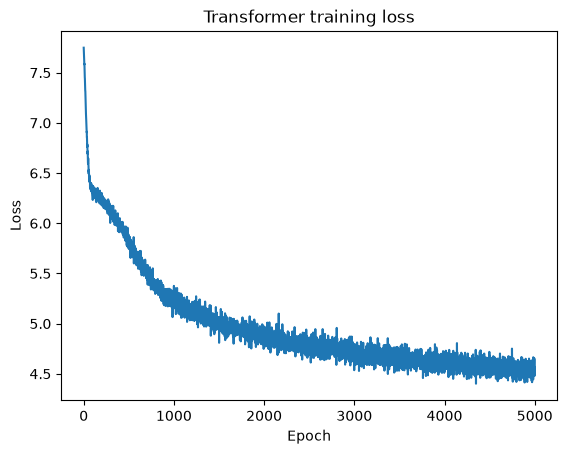

In [37]:
transformer_optimizer = torch.optim.Adam(transformer_model.parameters(), lr=1e-3)
transformer_criterion = nn.CrossEntropyLoss()
transformer_losses = []
transformer_data = encoded.to(device)

transformer_epochs = 5000
transformer_model.train()
for epoch in range(transformer_epochs):
    xb, yb = get_batch(transformer_data, batch_size=32, block_size=transformer_model.context_size)
    logits, _ = transformer_model(xb)
    loss = transformer_criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))

    transformer_optimizer.zero_grad()
    loss.backward()
    transformer_optimizer.step()
    transformer_losses.append(loss.item())

    if epoch % 500 == 0 or epoch == transformer_epochs - 1:
        print(f'epoch {epoch:4d} | loss = {loss.item():.4f}')

plt.plot(transformer_losses)
plt.title('Transformer training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [39]:
transformer_text = generate_transformer(
    transformer_model, 'Age of Middle-earth ', 1200, device,
)
print(transformer_text)

Age of Middle-earthancing the Shire, and the By of the other side of the other side of the Forest of the sun of the Houses. Angmn's, and the ruil. The Barge of the Hashed and his heads of the Brom of the Great River, and the hideing of the walls of the costs of the Havered. Age, and the Highing and the Ring, and the shores of the same of the Shire, and the end of the wise, and the Riders of the past of the rumen of the hill. But the House of the air of the Halfy of the Highs of the mountains of the Halfy, and the Warden of the Great River, and the Elendil, and the Hill of the falls of the Hays of the Sning. There was a greater of the air of the Ring of the same past, and bit of the Highing. The hobbits of the twagging of the Moon, and the Mountain, and the Gate were round the Frays, and the Ring, and the stars. The hobbits were up the Ring, and the road of the Dark Tower of the other first of the hobbits of the bigures of the sky. The Wormtched the faces of the truth of the ground of t